# 🍎 Nhận dạng trái cây bằng CNN (Convolutional Neural Network)

**Đồ án môn học** — Xây dựng mô hình CNN tự động nhận dạng trái cây.

Notebook này được viết cho người **mới học CNN lần đầu**. Mỗi bước đều có giải thích bằng tiếng Việt trước khi viết code, để bạn hiểu **vì sao** làm chứ không chỉ chạy theo.

## Nội dung
1. Chuẩn bị môi trường (bật GPU trên Colab)
2. Tải bộ dữ liệu ảnh trái cây (Fruits-360)
3. CNN là gì? (giải thích khái niệm)
4. Nạp và xem trước dữ liệu ảnh
5. Xây dựng CNN từ đầu (Simple CNN)
6. Huấn luyện và đánh giá Simple CNN
7. Transfer Learning (MobileNetV2) — để tăng độ chính xác
8. Đánh giá mô hình cuối cùng (confusion matrix, classification report)
9. Lưu mô hình & thử dự đoán ảnh mới
10. Nộp bài lên GitHub

> 💡 **Chạy trên Google Colab**: Menu `Runtime` → `Change runtime type` → chọn **GPU** (T4) → Save. Việc này giúp train nhanh hơn rất nhiều so với CPU.


## 1. Chuẩn bị môi trường

Các thư viện dưới đây đã có sẵn trên Google Colab, không cần cài thêm gì nhiều. Ta chỉ cần cài `kagglehub` để tải dataset.

In [1]:
!pip install -q kagglehub

import os, glob, shutil, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import re
from collections import defaultdict

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"Đã bật memory growth cho {len(gpus)} GPU")

print("TensorFlow version:", tf.__version__)
print("GPU có sẵn:", tf.config.list_physical_devices('GPU'))


I0000 00:00:1791820566.769308    2517 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791820566.798797    2517 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791820567.587536    2517 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Đã bật memory growth cho 1 GPU
TensorFlow version: 2.22.0-rc0
GPU có sẵn: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Tải bộ dữ liệu Fruits-360

Ta dùng bộ dữ liệu **Fruits-360** trên Kaggle — khoảng 90.000 ảnh, hơn 130 loại trái cây, ảnh đã được tách nền sẵn nên rất dễ train (phù hợp cho đồ án nhập môn).

Nguồn: https://www.kaggle.com/datasets/moltean/fruits

### Cách tải (kagglehub)
Khi chạy ô code dưới đây lần đầu, Colab có thể yêu cầu bạn đăng nhập Kaggle (nhập **Kaggle username** và **API key**):
1. Vào https://www.kaggle.com/ → đăng nhập/đăng ký (miễn phí)
2. Vào **Settings** (bấm avatar góc phải → Settings) → mục **API** → bấm **Create New Token** → file `kaggle.json` sẽ tải về
3. Mở file `kaggle.json` bằng Notepad để lấy `username` và `key`, dán vào khi Colab hỏi (hoặc dùng lệnh `kagglehub.login()`)

Nếu không muốn làm bước này, xem **Cách 2** ở ô ghi chú bên dưới ô code.

In [2]:
import kagglehub

# Tải dataset Fruits-360 (bản mới nhất). Lần đầu sẽ mất vài phút để tải (~1-2GB).
dataset_path = kagglehub.dataset_download("moltean/fruits")
print("Dataset đã tải về tại:", dataset_path)

# Tự động tìm 2 thư mục Training và Test bên trong (vì cấu trúc dataset có thể lồng nhau)
def find_dir(root, name):
    matches = [p for p in glob.glob(os.path.join(root, "**", name), recursive=True) if os.path.isdir(p)]
    if not matches:
        raise FileNotFoundError(f"Không tìm thấy thư mục '{name}' trong {root}")
    # ưu tiên đường dẫn ngắn nhất (thường là đúng cấp thư mục gốc của dataset)
    matches.sort(key=len)
    return matches[0]

TRAIN_DIR = find_dir(dataset_path, "Training")
TEST_DIR  = find_dir(dataset_path, "Test")
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR :", TEST_DIR)

all_classes = sorted(os.listdir(TRAIN_DIR))
print(f"Tổng số loại trái cây trong dataset: {len(all_classes)}")
print("Vài ví dụ:", all_classes[:10])


Dataset đã tải về tại: /home/tranduydang/.cache/kagglehub/datasets/moltean/fruits/versions/107
TRAIN_DIR: /home/tranduydang/.cache/kagglehub/datasets/moltean/fruits/versions/107/fruits-360_100x100/fruits-360/Training
TEST_DIR : /home/tranduydang/.cache/kagglehub/datasets/moltean/fruits/versions/107/fruits-360_100x100/fruits-360/Test
Tổng số loại trái cây trong dataset: 268
Vài ví dụ: ['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20']


> **Cách 2 (nếu Cách 1 lỗi vì không đăng nhập được Kaggle):**
> ```python
> from google.colab import files
> files.upload()  # chọn file kaggle.json vừa tải về
> !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
> !pip install -q kaggle
> !kaggle datasets download -d moltean/fruits -p /content/fruits360 --unzip
> ```
> Sau đó tự đặt `TRAIN_DIR` và `TEST_DIR` trỏ vào thư mục `/content/fruits360/.../Training` và `.../Test`.

### Vì sao chỉ dùng một số ít loại trái cây để bắt đầu?
Dataset gốc có hơn 130 loại (kể cả các biến thể như "Apple Braeburn", "Apple Golden 1"...). Để việc train nhanh và dễ theo dõi kết quả khi mới học, ta sẽ **chọn ra một số lượng loại nhỏ hơn** trước. Sau khi mọi thứ chạy ổn, bạn có thể tăng `SUBSET_CLASSES` lên hoặc đặt `None` để dùng toàn bộ dataset.

In [3]:
SUBSET_CLASSES = 15   # đặt = None nếu muốn dùng TẤT CẢ các loại trái cây có trong dataset
SEED = 42
random.seed(SEED)

def base_name(cls):
    # Bỏ số ở cuối tên để gộp các biến thể cùng 1 loại (vd: "Apple 23" -> "Apple")
    return re.sub(r'\s*\d+$', '', cls).strip()

def group_key(cls):
    # Chuẩn hoá hoa/thường để gộp đúng các biến thể viết hoa khác nhau
    # (vd: "Grape Pink" và "grape pink" phải là CÙNG 1 loại, không phải 2 loại)
    return base_name(cls).lower()

groups = defaultdict(list)
display_name = {}
for cls in all_classes:
    key = group_key(cls)
    groups[key].append(cls)
    display_name.setdefault(key, base_name(cls))  # giữ tên hiển thị đẹp (lần gặp đầu tiên)

print(f"Số loại trái cây THỰC SỰ (đã gộp đúng, không phân biệt hoa-thường): {len(groups)}")

if SUBSET_CLASSES is not None:
    selected_keys = sorted(random.sample(list(groups.keys()), SUBSET_CLASSES))
else:
    selected_keys = sorted(groups.keys())

selected_fruits = [display_name[k] for k in selected_keys]
print(f"Số loại trái cây được chọn để train: {len(selected_fruits)}")
print(selected_fruits)

BASE_DIR = os.path.expanduser("~/fruit-cnn-project")
FILTERED_TRAIN = os.path.join(BASE_DIR, "fruits_subset", "Training")
FILTERED_TEST  = os.path.join(BASE_DIR, "fruits_subset", "Test")
shutil.rmtree(os.path.join(BASE_DIR, "fruits_subset"), ignore_errors=True)

def link_images(variant_names, src_root, dst_dir):
    os.makedirs(dst_dir, exist_ok=True)
    for variant in variant_names:
        src_dir = os.path.join(src_root, variant)
        for fname in os.listdir(src_dir):
            dst_path = os.path.join(dst_dir, f"{variant}_{fname}")
            if not os.path.exists(dst_path):
                os.symlink(os.path.join(src_dir, fname), dst_path)

for key, fruit in zip(selected_keys, selected_fruits):
    link_images(groups[key], TRAIN_DIR, os.path.join(FILTERED_TRAIN, fruit))
    link_images(groups[key], TEST_DIR,  os.path.join(FILTERED_TEST, fruit))

n_train_imgs = sum(len(files) for _, _, files in os.walk(FILTERED_TRAIN))
n_test_imgs  = sum(len(files) for _, _, files in os.walk(FILTERED_TEST))
print(f"Số ảnh train: {n_train_imgs} | Số ảnh test: {n_test_imgs}")

Số loại trái cây THỰC SỰ (đã gộp đúng, không phân biệt hoa-thường): 143
Số loại trái cây được chọn để train: 15
['Apple Pink Lady', 'Apple Red', 'Apple Red Delicious', 'Cabbage white', 'Cactus fruit', 'Caju seed', 'Carambola', 'Cherry Sour', 'Grape Blue', 'Grape White', 'Grapefruit White', 'Huckleberry', 'Lychee', 'Physalis', 'Zucchini']
Số ảnh train: 10729 | Số ảnh test: 3592


## 3. CNN là gì? (Giải thích ngắn gọn)

**CNN (Convolutional Neural Network — Mạng nơ-ron tích chập)** là loại mạng học sâu chuyên xử lý ảnh. Ý tưởng cốt lõi, đúng theo tinh thần bài giảng của cô (AlexNet/VGG):

| Thành phần | Vai trò | Ví dụ đời thường |
|---|---|---|
| **Convolution (tích chập)** | Trượt các bộ lọc nhỏ (kernel, vd 3×3) qua ảnh để phát hiện đặc trưng (cạnh, màu, hoa văn) | Giống việc bạn nhìn từng mảng nhỏ của quả táo để nhận ra đường viền, màu đỏ |
| **ReLU (activation)** | Giữ lại tín hiệu "có ý nghĩa", loại bỏ giá trị âm | Chỉ chú ý các đặc trưng nổi bật |
| **Pooling (vd MaxPooling)** | Thu nhỏ ảnh đặc trưng lại, giữ thông tin quan trọng nhất | Nhìn tổng quát hơn, bỏ qua chi tiết vụn vặt |
| **Fully Connected / Dense** | Tổng hợp toàn bộ đặc trưng đã học để đưa ra quyết định cuối | "Với các đặc trưng này, đây là quả **chuối**" |

Một mạng CNN thường xếp chồng nhiều khối **Conv → ReLU → Pooling** liên tiếp:
- Các lớp **đầu** (gần ảnh input) học đặc trưng **low-level**: cạnh, đường thẳng, màu sắc
- Các lớp **giữa** học đặc trưng **mid-level**: hình dạng cong, kết cấu bề mặt
- Các lớp **cuối** học đặc trưng **high-level**: hình dáng tổng thể của quả, đủ để phân biệt táo với cam
- Cuối cùng, một vài lớp **Dense (fully connected)** đóng vai trò "bộ phân loại" — nhìn vào các đặc trưng cấp cao đó và dự đoán tên loại trái cây.

Đây chính xác là những gì bạn sẽ thấy khi ta xây model ở Bước 5 bên dưới — mỗi khối `Conv2D + ReLU + MaxPooling` lặp lại 3 lần, sau đó là `Flatten + Dense`.

## 4. Nạp và xem trước dữ liệu ảnh

Ta dùng `image_dataset_from_directory` của Keras: hàm này tự động đọc ảnh từ các thư mục con (mỗi thư mục con = 1 nhãn/loại trái cây), resize ảnh, và gộp thành từng batch để train.

In [4]:
IMG_SIZE = (100, 100)   # Fruits-360 ảnh gốc là 100x100
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    FILTERED_TRAIN,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    FILTERED_TRAIN,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    FILTERED_TEST,
    shuffle=False,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Các lớp (nhãn):", class_names)


Found 10729 files belonging to 15 classes.
Using 8584 files for training.


I0000 00:00:1791820584.745683    2517 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9711 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 10729 files belonging to 15 classes.
Using 2145 files for validation.
Found 3592 files belonging to 15 classes.
Các lớp (nhãn): ['Apple Pink Lady', 'Apple Red', 'Apple Red Delicious', 'Cabbage white', 'Cactus fruit', 'Caju seed', 'Carambola', 'Cherry Sour', 'Grape Blue', 'Grape White', 'Grapefruit White', 'Huckleberry', 'Lychee', 'Physalis', 'Zucchini']


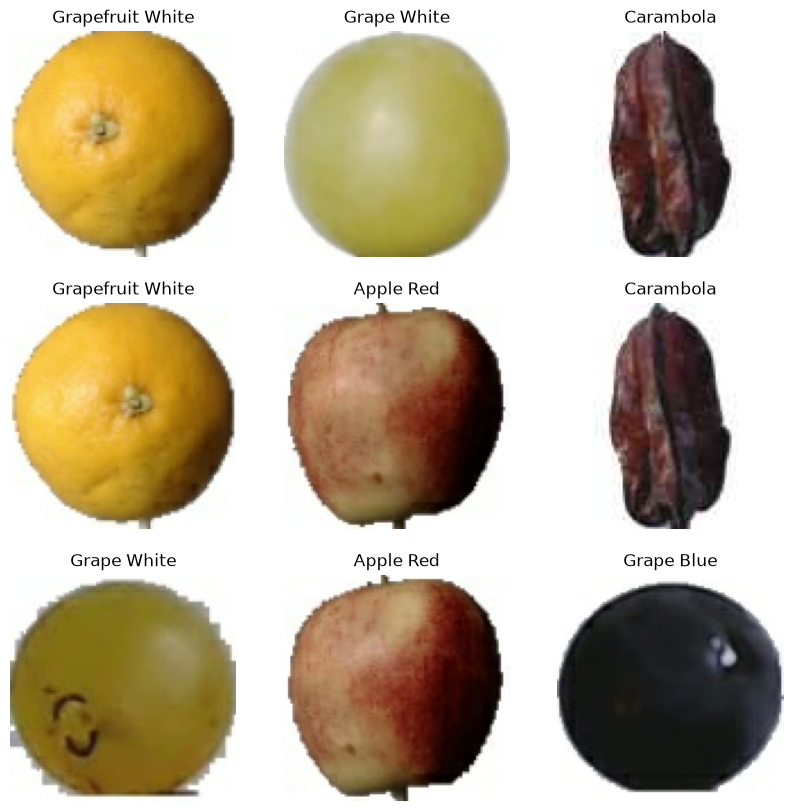

In [5]:
# Xem thử vài ảnh trong tập train
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()


In [6]:
# Tối ưu tốc độ đọc dữ liệu + chuẩn hoá pixel về khoảng [0,1] + data augmentation nhẹ để chống overfitting
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

normalization_layer = layers.Rescaling(1./255)

def prepare(ds, training=False):
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=AUTOTUNE)
    return ds.cache().prefetch(buffer_size=AUTOTUNE)

train_ds_prepared = prepare(train_ds, training=True)
val_ds_prepared   = prepare(val_ds)
test_ds_prepared  = prepare(test_ds)


## 5. Xây dựng CNN từ đầu (Simple CNN)

Đây là kiến trúc CNN đơn giản, đúng tinh thần bài giảng: 3 khối `Conv2D → ReLU → MaxPooling` (đặc trưng thấp → cao dần), sau đó `Flatten` rồi qua các lớp `Dense` để phân loại. `Dropout` giúp chống overfitting (mô hình học vẹt dữ liệu train).

In [7]:
def build_simple_cnn(input_shape, num_classes):
    model = keras.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, activation="relu"),
        layers.MaxPooling2D(),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax"),
    ])
    return model

simple_model = build_simple_cnn(IMG_SIZE + (3,), num_classes)
simple_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
simple_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,733,711 (6.61 MB)

 Trainable params: 1,733,711 (6.61 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Huấn luyện và đánh giá Simple CNN

`EarlyStopping` sẽ tự động dừng train khi mô hình không còn cải thiện trên tập validation, tránh mất thời gian và overfitting.

In [8]:
EPOCHS = 15

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history = simple_model.fit(
    train_ds_prepared,
    validation_data=val_ds_prepared,
    epochs=EPOCHS,
    callbacks=[early_stop],
)


Epoch 1/15


/home/tranduydang/fruit-cnn-project/venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791820590.198020    2517 service.cc:154] XLA service 0x1c268190 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791820590.198054    2517 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 3060, Compute Capability 8.6 (Driver: 12.6.0[560.94.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1791820590.230933    2517 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791820590.682420    2517 cuda_dnn.cc:442] Loaded cuDNN version 92600
W0000 00:00:1791820596.734217    2888 cuda_time

 16/269 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.3027 - loss: 2.2792

I0000 00:00:1791820600.115823    2517 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
W0000 00:00:1791820600.141066    2517 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791820589627339221 in buffer 'PrefetchDataset/_28' sat unconsumed for 10.5058 seconds!


269/269 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.8573 - loss: 0.4751 - val_accuracy: 0.9907 - val_loss: 0.0273
Epoch 2/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9708 - loss: 0.0921 - val_accuracy: 0.9944 - val_loss: 0.0179
Epoch 3/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9868 - loss: 0.0437 - val_accuracy: 0.9967 - val_loss: 0.0100
Epoch 4/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9885 - loss: 0.0334 - val_accuracy: 0.9897 - val_loss: 0.0215
Epoch 5/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9889 - loss: 0.0361 - val_accuracy: 0.9953 - val_loss: 0.0137
Epoch 6/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9910 - loss: 0.0320 - val_accuracy: 0.9986 - val_loss: 0.0043
Epoch 7/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9917 - loss: 0.0304 - val_accuracy: 0.9986 - val_loss: 0.0018
Epoch 8/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9957 - loss: 0.0129 - val_accuracy: 0.99

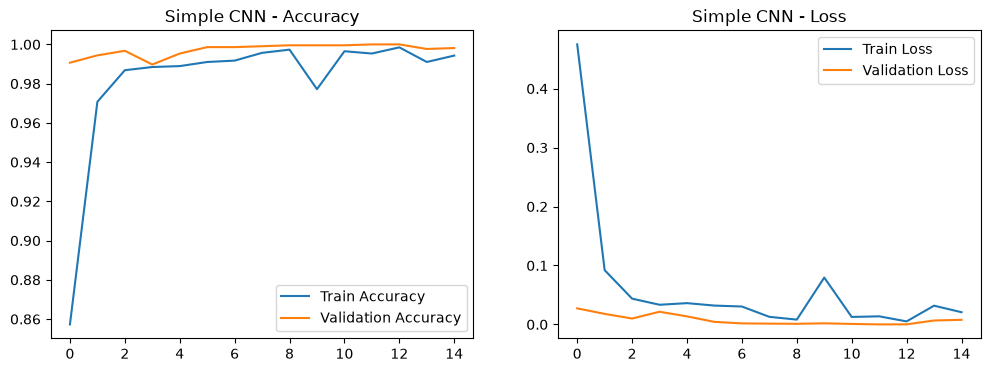

113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 1.0000 - loss: 0.0013
Simple CNN — Test accuracy: 1.0000


In [9]:
def plot_history(history, title=""):
    acc = history.history["accuracy"]
    val_acc = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label="Train Accuracy")
    plt.plot(epochs_range, val_acc, label="Validation Accuracy")
    plt.legend()
    plt.title(f"{title} - Accuracy")

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label="Train Loss")
    plt.plot(epochs_range, val_loss, label="Validation Loss")
    plt.legend()
    plt.title(f"{title} - Loss")
    plt.show()

plot_history(history, "Simple CNN")

test_loss, test_acc = simple_model.evaluate(test_ds_prepared)
print(f"Simple CNN — Test accuracy: {test_acc:.4f}")


## 7. Transfer Learning với MobileNetV2 (để tăng độ chính xác)

**Transfer Learning** = tận dụng một mạng CNN đã được huấn luyện sẵn trên hàng triệu ảnh (ImageNet) — mạng đó đã "biết" cách nhận diện cạnh, hình dạng, kết cấu rất tốt rồi. Ta chỉ cần **giữ nguyên phần trích xuất đặc trưng** (backbone) và **huấn luyện lại phần phân loại cuối** cho bài toán trái cây của mình.

Ưu điểm: học nhanh hơn, chính xác hơn, cần ít dữ liệu hơn so với train CNN từ đầu — rất phù hợp khi dataset không quá lớn.

In [10]:
IMG_SIZE_TL = (128, 128)

# Nạp lại dữ liệu với kích thước ảnh phù hợp cho MobileNetV2
train_ds_tl = tf.keras.utils.image_dataset_from_directory(
    FILTERED_TRAIN, validation_split=0.2, subset="training",
    seed=SEED, image_size=IMG_SIZE_TL, batch_size=BATCH_SIZE)
val_ds_tl = tf.keras.utils.image_dataset_from_directory(
    FILTERED_TRAIN, validation_split=0.2, subset="validation",
    seed=SEED, image_size=IMG_SIZE_TL, batch_size=BATCH_SIZE)
test_ds_tl = tf.keras.utils.image_dataset_from_directory(
    FILTERED_TEST, shuffle=False, image_size=IMG_SIZE_TL, batch_size=BATCH_SIZE)

train_ds_tl_p = train_ds_tl.map(lambda x, y: (data_augmentation(x, training=True), y)).cache().prefetch(AUTOTUNE)
val_ds_tl_p   = val_ds_tl.cache().prefetch(AUTOTUNE)
test_ds_tl_p  = test_ds_tl.cache().prefetch(AUTOTUNE)

base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE_TL + (3,),
    include_top=False,       # bỏ lớp phân loại gốc (1000 lớp ImageNet)
    weights="imagenet",
)
base_model.trainable = False  # đóng băng backbone, chỉ train phần đầu ra mới

inputs = keras.Input(shape=IMG_SIZE_TL + (3,))
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
tl_model = keras.Model(inputs, outputs)

tl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
tl_model.summary()


Found 10729 files belonging to 15 classes.
Using 8584 files for training.
Found 10729 files belonging to 15 classes.
Using 2145 files for validation.
Found 3592 files belonging to 15 classes.


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
268/269 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.9494 - loss: 0.2360

W0000 00:00:1791820672.733345    6063 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


269/269 ━━━━━━━━━━━━━━━━━━━━ 35s 104ms/step - accuracy: 0.9494 - loss: 0.2358 - val_accuracy: 1.0000 - val_loss: 0.0319
Epoch 2/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9997 - loss: 0.0169 - val_accuracy: 1.0000 - val_loss: 0.0151
Epoch 3/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9998 - loss: 0.0083 - val_accuracy: 1.0000 - val_loss: 0.0094
Epoch 4/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9999 - loss: 0.0051 - val_accuracy: 1.0000 - val_loss: 0.0067
Epoch 5/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9999 - loss: 0.0035 - val_accuracy: 1.0000 - val_loss: 0.0051
Epoch 6/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 1.0000 - loss: 0.0025 - val_accuracy: 1.0000 - val_loss: 0.0041
Epoch 7/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 1.0000 - loss: 0.0019 - val_accuracy: 1.0000 - val_loss: 0.0034
Epoch 8/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 1.0

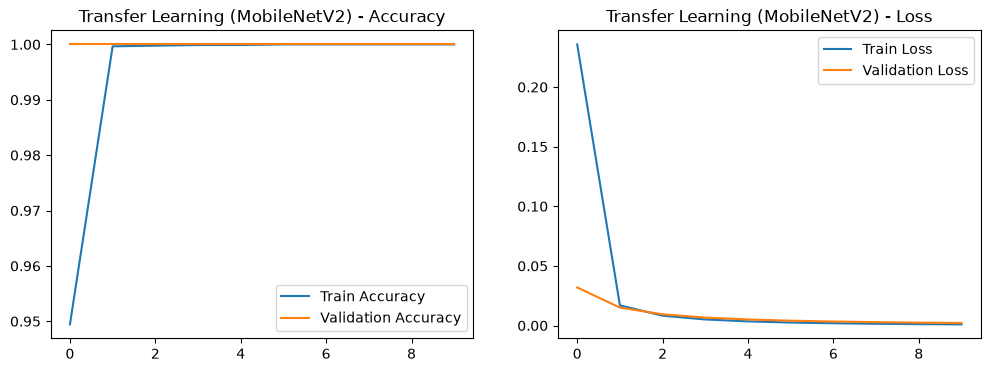

113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 1.0000 - loss: 0.0043
Transfer Learning — Test accuracy: 1.0000


In [11]:
history_tl = tl_model.fit(
    train_ds_tl_p,
    validation_data=val_ds_tl_p,
    epochs=10,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
)

plot_history(history_tl, "Transfer Learning (MobileNetV2)")

test_loss_tl, test_acc_tl = tl_model.evaluate(test_ds_tl_p)
print(f"Transfer Learning — Test accuracy: {test_acc_tl:.4f}")


### (Tuỳ chọn) Fine-tuning
Nếu muốn độ chính xác cao hơn nữa, có thể "rã đông" một vài lớp cuối của `base_model` và train tiếp với learning rate rất nhỏ:
```python
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

tl_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
tl_model.fit(train_ds_tl_p, validation_data=val_ds_tl_p, epochs=5)
```
Bước này không bắt buộc — chỉ làm nếu bạn muốn cải thiện thêm điểm số và có thời gian.

## 8. Đánh giá mô hình chi tiết

So sánh 2 mô hình bằng **confusion matrix** và **classification report** (precision, recall, f1-score cho từng loại trái cây) — dùng cho phần báo cáo đồ án.

113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step
                     precision    recall  f1-score   support

    Apple Pink Lady       1.00      1.00      1.00       152
          Apple Red       1.00      1.00      1.00       472
Apple Red Delicious       1.00      1.00      1.00       166
      Cabbage white       1.00      1.00      1.00        47
       Cactus fruit       1.00      1.00      1.00       166
          Caju seed       1.00      1.00      1.00        75
          Carambola       1.00      1.00      1.00       642
        Cherry Sour       1.00      1.00      1.00       150
         Grape Blue       1.00      1.00      1.00       328
        Grape White       1.00      1.00      1.00       654
   Grapefruit White       1.00      1.00      1.00       164
        Huckleberry       1.00      1.00      1.00       166
             Lychee       1.00      1.00      1.00       166
           Physalis       1.00      1.00      1.00       164
           Zucchini       1.00      1.00  

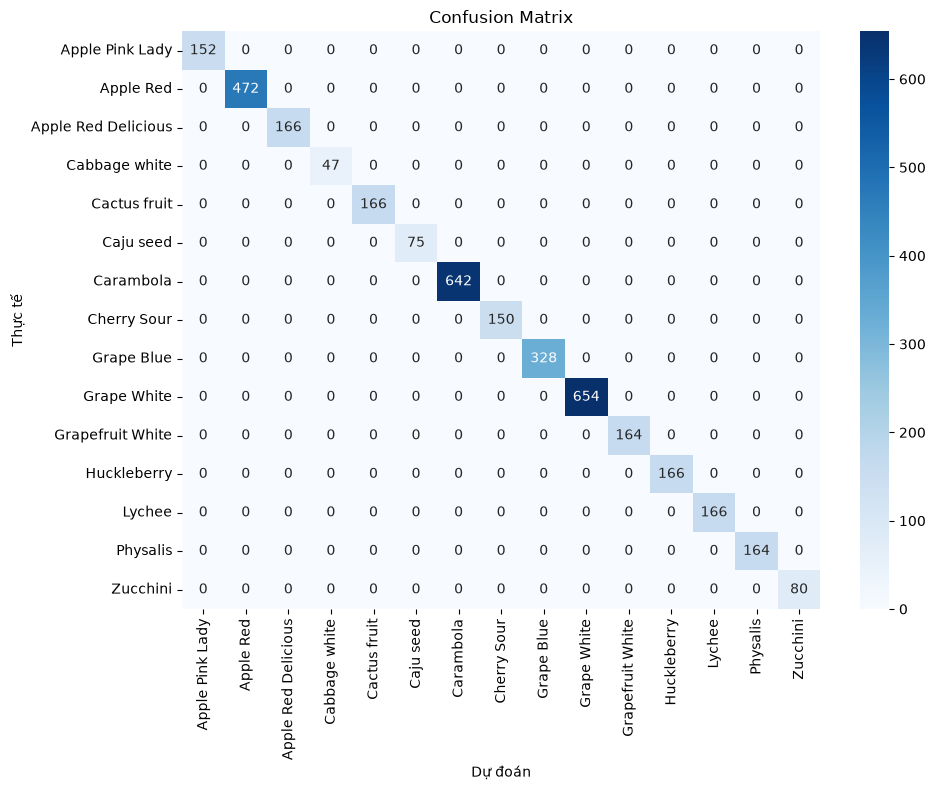

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Chọn mô hình để đánh giá chi tiết (đổi thành simple_model / test_ds_prepared nếu muốn xem CNN tự xây)
best_model = tl_model
eval_ds = test_ds_tl  # dùng bản chưa augment, chưa cache map lần 2 để lấy đúng nhãn gốc

y_true = np.concatenate([y.numpy() for _, y in eval_ds])
y_pred_probs = best_model.predict(eval_ds.map(lambda x, y: keras.applications.mobilenet_v2.preprocess_input(x)) if False else eval_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=len(class_names) <= 15, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.title("Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 9. Lưu mô hình & thử dự đoán ảnh mới

Lưu mô hình lại (định dạng `.keras`) để nộp bài / dùng lại sau này mà không cần train lại từ đầu.

In [13]:
BASE_DIR = os.path.expanduser("~/fruit-cnn-project")
MODEL_DIR = os.path.join(BASE_DIR, "model")
os.makedirs(MODEL_DIR, exist_ok=True)
tl_model.save(os.path.join(MODEL_DIR, "fruit_cnn_mobilenetv2.keras"))
print("Đã lưu model tại:", os.path.join(MODEL_DIR, "fruit_cnn_mobilenetv2.keras"))

import json as _json
with open(os.path.join(MODEL_DIR, "class_names.json"), "w", encoding="utf-8") as f:
    _json.dump(class_names, f, ensure_ascii=False, indent=2)
print("Đã lưu danh sách lớp.")

Đã lưu model tại: /home/tranduydang/fruit-cnn-project/model/fruit_cnn_mobilenetv2.keras
Đã lưu danh sách lớp.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


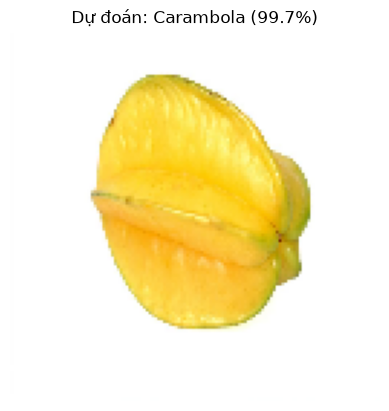

In [20]:
from tensorflow.keras.preprocessing import image as keras_image

# Đổi đường dẫn dưới đây thành ảnh trái cây bạn muốn thử (xem hướng dẫn cách đưa ảnh vào bên dưới)
IMG_PATH = os.path.expanduser("~/fruit-cnn-project/test_images/test_image_5.jpg")

img = keras_image.load_img(IMG_PATH, target_size=IMG_SIZE_TL)
img_array = keras_image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

pred = tl_model.predict(img_array)
pred_class = class_names[np.argmax(pred)]
confidence = np.max(pred) * 100

plt.imshow(img)
plt.axis("off")
plt.title(f"Dự đoán: {pred_class} ({confidence:.1f}%)")
plt.show()

## 10. Nộp bài lên GitHub

Xem hướng dẫn chi tiết, từng bước bằng hình + không cần biết dòng lệnh Git nào, trong file **`HUONG_DAN_NOP_GITHUB.md`** đi kèm trong bộ project này.

Tóm tắt nhanh (cách dễ nhất, không cần cài Git):
1. Tải file notebook này về máy: `File → Download → Download .ipynb`
2. Tạo tài khoản GitHub (nếu chưa có) tại https://github.com
3. Tạo repository mới (nút **New**), đặt tên vd `fruit-cnn-classification`
4. Vào repo vừa tạo → **Add file → Upload files** → kéo thả file `.ipynb`, `README.md`, ảnh kết quả (confusion matrix, biểu đồ accuracy) vào
5. Bấm **Commit changes** → xong! Gửi link repo cho cô là được.

> 💡 Mẹo: Chụp lại (screenshot) biểu đồ accuracy/loss và confusion matrix ở các bước trên, lưu vào 1 thư mục `results/` rồi upload cùng — báo cáo sẽ trực quan và thuyết phục hơn.